# PSO, ACO and GWO

the same genome, fitness, cache and budget as the ga and random search notebook, 2 runs each. each run's top 3 are retrained on all of train and scored on val.

In [1]:
!pip install -q pennylane==0.45.1

import os
# one thread per process, set before torch loads
os.environ["OMP_NUM_THREADS"] = "1"
import time
import json
import multiprocessing as mp
import numpy as np
import pandas as pd
import torch
import pennylane as qml
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score

seed = 0
np.random.seed(seed)
torch.set_num_threads(1)

prep_dir = "/kaggle/input/datasets/malakkhaled202300369/nic-feature-dataset/prep"
out_dir = "/kaggle/working/more_search"
os.makedirs(out_dir, exist_ok=True)

algorithms = ["PSO", "ACO", "GWO"]   # a subset can run on each account
n_runs = 2
budget = 300                  # distinct genomes per run
pop_size = 20                 # particles, ants or wolves
top_k = 3
max_depth = 4
lam = 0.0006                  # penalty per two-qubit gate
# short training picked by the grid's ranking check
fit_lr = 0.03
fit_epochs = 6
lr = 0.01
epochs = 5
batch_size = 256
# pso, clerc and kennedy constriction with phi 4.1: chi 0.729844, c = 2.05 * chi
inertia = 0.7298
c1 = 1.49618
c2 = 1.49618
v_max = 0.2
# aco
rho = 0.1
tau_min = 0.1
tau_max = 5.0
encodings = ["RX", "RY", "H+RZ"]
rotations = ["RY", "RX+RY", "Rot"]
entanglers = ["none", "chain", "ring", "cz_ring"]

In [2]:
angles = {}
meta = {}
for split in ["train", "val"]:
    angles[split] = np.load(f"{prep_dir}/ffpp_{split}_angles32.npy").astype(np.float64)
    meta[split] = pd.read_csv(f"{prep_dir}/ffpp_{split}_rows.csv")

is_inner = np.load(f"{prep_dir}/ffpp_train_is_inner.npy").astype(bool)
comp = pd.read_csv(f"{prep_dir}/per_component_auc.csv")
best8 = sorted(comp.sort_values("strength_search_train", ascending=False)["component"].head(8).tolist())
first8 = list(range(8))

y_train = meta["train"]["label"].to_numpy()
y_val = meta["val"]["label"].to_numpy()
# a video is (method, video_id), the 4 fakes of one pair share a video_id
val_video = meta["val"].groupby(["method", "video_id"]).ngroup().to_numpy()

## fitness frames

the search trains each genome on 2000 search-train frames (1000 real, 1000 fake, at most 2 per real video and 1 per fake video) and scores it by auc on the inner fitness frames.

In [3]:
search_idx = np.where(~is_inner)[0]
inner_idx = np.where(is_inner)[0]

st = meta["train"].iloc[search_idx].copy()
st["row"] = search_idx
real_pick = st[st["label"] == 0].groupby("video_id").sample(n=2, random_state=0)["row"].to_numpy()
fake_pick = st[st["label"] == 1].groupby(["method", "video_id"]).sample(n=1, random_state=0)["row"].to_numpy()
rng = np.random.default_rng(0)
sub = np.concatenate([rng.choice(real_pick, 1000, replace=False), rng.choice(fake_pick, 1000, replace=False)])

## the circuit from a genome

a genome is the 8 components (to qubits 0 to 7 in ascending order), the encoding, and per layer a rotation and an entangler. readout is <z> on all 8 qubits, then a weighted sum and a bias.

In [4]:
n_qubits = 8
gates_per_layer = {"none": 0, "chain": n_qubits - 1, "ring": n_qubits, "cz_ring": n_qubits}
angles_per_rot = {"RY": 1, "RX+RY": 2, "Rot": 3}


def make_genome(mask, encoding, layers):
    return {"mask": sorted(mask), "encoding": encoding, "layers": [{"rotation": r, "entangler": e} for r, e in layers]}


def two_qubit_gates(g):
    return sum(gates_per_layer[layer["entangler"]] for layer in g["layers"])


def n_weights(g):
    return sum(n_qubits * angles_per_rot[layer["rotation"]] for layer in g["layers"]) + n_qubits + 1


def build_circuit(g):
    dev = qml.device("default.qubit", wires=n_qubits)

    @qml.qnode(dev, interface="torch", diff_method="backprop")
    def circuit(x, ws):
        for i in range(n_qubits):
            if g["encoding"] == "RX":
                qml.RX(x[:, i], wires=i)
            elif g["encoding"] == "RY":
                qml.RY(x[:, i], wires=i)
            else:
                qml.Hadamard(wires=i)
                qml.RZ(x[:, i], wires=i)
        for layer, w in zip(g["layers"], ws):
            for i in range(n_qubits):
                if layer["rotation"] == "RY":
                    qml.RY(w[i, 0], wires=i)
                elif layer["rotation"] == "RX+RY":
                    qml.RX(w[i, 0], wires=i)
                    qml.RY(w[i, 1], wires=i)
                else:
                    qml.Rot(w[i, 0], w[i, 1], w[i, 2], wires=i)
            if layer["entangler"] == "chain":
                for i in range(n_qubits - 1):
                    qml.CNOT(wires=[i, i + 1])
            elif layer["entangler"] == "ring":
                for i in range(n_qubits):
                    qml.CNOT(wires=[i, (i + 1) % n_qubits])
            elif layer["entangler"] == "cz_ring":
                for i in range(n_qubits):
                    qml.CZ(wires=[i, (i + 1) % n_qubits])
        return [qml.expval(qml.PauliZ(i)) for i in range(n_qubits)]

    return circuit


class QuantumClassifier(torch.nn.Module):
    def __init__(self, g):
        super().__init__()
        self.circuit = build_circuit(g)
        self.rot = torch.nn.ParameterList()
        for layer in g["layers"]:
            k = angles_per_rot[layer["rotation"]]
            self.rot.append(torch.nn.Parameter(0.1 * torch.randn(n_qubits, k, dtype=torch.float64)))
        self.readout = torch.nn.Linear(n_qubits, 1, dtype=torch.float64)
        torch.nn.init.normal_(self.readout.weight, std=0.1)
        torch.nn.init.zeros_(self.readout.bias)

    def forward(self, x):
        out = torch.stack(self.circuit(x, list(self.rot)), dim=1).to(torch.float64)
        return self.readout(out).squeeze(1)


def train(model, x, y, lr=0.01, epochs=5, batch_size=256, seed=0):
    g = torch.Generator().manual_seed(seed)
    x = torch.as_tensor(x, dtype=torch.float64)
    y = torch.as_tensor(y, dtype=torch.float64)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    loss_fn = torch.nn.BCEWithLogitsLoss()
    for epoch in range(epochs):
        order = torch.randperm(len(x), generator=g)
        for start in range(0, len(x), batch_size):
            idx = order[start:start + batch_size]
            opt.zero_grad()
            loss_fn(model(x[idx]), y[idx]).backward()
            opt.step()


def predict(model, x, batch_size=4096):
    out = []
    with torch.no_grad():
        for s in range(0, len(x), batch_size):
            xb = torch.as_tensor(x[s:s + batch_size], dtype=torch.float64)
            out.append(torch.sigmoid(model(xb)))
    return torch.cat(out).numpy()

In [5]:
def video_level(prob):
    df = pd.DataFrame({"video": val_video, "p": prob, "y": y_val})
    g = df.groupby("video").agg(p=("p", "mean"), y=("y", "first"))
    return g["p"].to_numpy(), g["y"].to_numpy()


def bootstrap_ci(p, y, n=1000, seed=0):
    rng = np.random.default_rng(seed)
    aucs = []
    while len(aucs) < n:
        idx = rng.integers(0, len(y), len(y))
        if y[idx].min() == y[idx].max():
            continue
        aucs.append(roc_auc_score(y[idx], p[idx]))
    return np.percentile(aucs, [2.5, 97.5])


def score(prob):
    pv, yv = video_level(prob)
    lo, hi = bootstrap_ci(pv, yv)
    return {"frame auc": roc_auc_score(y_val, prob), "video auc": roc_auc_score(yv, pv), "ci low": lo, "ci high": hi}

## genome, fitness and the cache

same as the search notebook, so every method is scored the same way.

In [6]:
def to_circuit(sg):
    return make_genome(sg["mask"], sg["encoding"], list(zip(sg["rotations"][:sg["depth"]], sg["entanglers"][:sg["depth"]])))


def key_of(sg):
    g = to_circuit(sg)
    layers = "-".join(f"{l['rotation']}/{l['entangler']}" for l in g["layers"])
    return "m" + ".".join(str(j) for j in g["mask"]) + "|" + g["encoding"] + "|" + layers


def fitness(sg):
    t0 = time.time()
    g = to_circuit(sg)
    cols = g["mask"]
    torch.manual_seed(0)
    model = QuantumClassifier(g)
    train(model, angles["train"][sub][:, cols], y_train[sub], lr=fit_lr, epochs=fit_epochs, batch_size=100, seed=0)
    auc = roc_auc_score(y_train[inner_idx], predict(model, angles["train"][inner_idx][:, cols]))
    gates = two_qubit_gates(g)
    return {"key": key_of(sg), "genome": json.dumps(sg), "inner auc": auc, "fitness": auc - lam * gates,
            "gates": gates, "weights": n_weights(g), "depth": sg["depth"], "seconds": time.time() - t0}


log = []


def evaluate(pool, genomes, cache, method, run):
    # a genome seen before costs nothing and is not counted
    new = []
    keys = set()
    for sg in genomes:
        k = key_of(sg)
        if k not in cache and k not in keys and len(cache) + len(new) < budget:
            new.append(sg)
            keys.add(k)
    for r in pool.map(fitness, new):
        cache[r["key"]] = r
        log.append(dict(r, method=method, run=run, eval=len(cache)))
    fit = []
    for sg in genomes:
        if key_of(sg) in cache:
            fit.append(cache[key_of(sg)]["fitness"])
        else:
            fit.append(None)
    return fit, len(new)

## random keys for pso and gwo

a position is 42 numbers in [0, 1]: 32 mask keys (the 8 largest win), then encoding, depth, 4 rotations and 4 entanglers. each gene's option order is shuffled per run, so a pull toward the middle of [0, 1] can't favour particular options.

In [7]:
n_dims = 32 + 2 + 2 * max_depth


def option_orders(rng):
    return {"encoding": rng.permutation(encodings).tolist(), "depth": rng.permutation([1, 2, 3, 4]).tolist(),
            "rotation": rng.permutation(rotations).tolist(), "entangler": rng.permutation(entanglers).tolist()}


def choose(v, options):
    i = int(v * len(options))
    if i == len(options):
        i = len(options) - 1
    return options[i]


def decode(pos, orders):
    return {"mask": sorted(np.argsort(-pos[:32])[:8].tolist()),
            "encoding": choose(pos[32], orders["encoding"]),
            "depth": int(choose(pos[33], orders["depth"])),
            "rotations": [choose(pos[34 + s], orders["rotation"]) for s in range(max_depth)],
            "entanglers": [choose(pos[34 + max_depth + s], orders["entangler"]) for s in range(max_depth)]}

## pso

In [8]:
def pso(pool, run):
    rng = np.random.default_rng(3000 + run)
    orders = option_orders(rng)
    cache = {}
    x = rng.random((pop_size, n_dims))
    v = rng.uniform(-v_max, v_max, (pop_size, n_dims))
    p_best = x.copy()
    p_fit = np.full(pop_size, -np.inf)
    g_best = x[0].copy()
    g_fit = -np.inf
    stale = 0
    while len(cache) < budget:
        fit, n_new = evaluate(pool, [decode(p, orders) for p in x], cache, "PSO", run)
        for i in range(pop_size):
            if fit[i] is None:
                continue
            if fit[i] > p_fit[i]:
                p_best[i] = x[i]
                p_fit[i] = fit[i]
            if fit[i] > g_fit:
                g_best = x[i].copy()
                g_fit = fit[i]
        if n_new == 0:
            stale += 1
        else:
            stale = 0
        if stale >= 20:
            print(f"pso run {run} stopped early at {len(cache)} genomes")
            break
        r1 = rng.random((pop_size, n_dims))
        r2 = rng.random((pop_size, n_dims))
        v = inertia * v + c1 * r1 * (p_best - x) + c2 * r2 * (g_best - x)
        v = np.clip(v, -v_max, v_max)
        x = np.clip(x + v, 0, 1)
    return cache

## gwo

the wolves move toward the three best positions found so far, and `a` falls from 2 to 0 as the budget is spent.

In [9]:
def gwo(pool, run):
    rng = np.random.default_rng(5000 + run)
    orders = option_orders(rng)
    cache = {}
    x = rng.random((pop_size, n_dims))
    leaders = []
    stale = 0
    while len(cache) < budget:
        fit, n_new = evaluate(pool, [decode(p, orders) for p in x], cache, "GWO", run)
        for i in range(pop_size):
            if fit[i] is not None:
                leaders.append((fit[i], x[i].copy()))
        leaders = sorted(leaders, key=lambda t: t[0], reverse=True)[:3]
        if n_new == 0:
            stale += 1
        else:
            stale = 0
        if stale >= 20:
            print(f"gwo run {run} stopped early at {len(cache)} genomes")
            break
        a = 2 - 2 * len(cache) / budget
        new_x = np.zeros((pop_size, n_dims))
        for _, leader in leaders:
            r1 = rng.random((pop_size, n_dims))
            r2 = rng.random((pop_size, n_dims))
            big_a = 2 * a * r1 - a
            big_c = 2 * r2
            new_x += leader - big_a * np.abs(big_c * leader - x)
        x = np.clip(new_x / len(leaders), 0, 1)
    return cache

## aco

each ant picks 8 components one at a time, then the encoding, depth and each layer's rotation and entangler, with chances set by pheromone. after each round pheromone evaporates, the round's best ant and the best so far each add 1, and values stay between `tau_min` and `tau_max` so the colony can't lock in early. no per-feature hint, like the ga and random search.

In [10]:
def new_tau():
    return {"mask": np.ones(32), "encoding": np.ones(len(encodings)), "depth": np.ones(max_depth),
            "rotation": np.ones((max_depth, len(rotations))), "entangler": np.ones((max_depth, len(entanglers)))}


def pick(weights, rng):
    return int(rng.choice(len(weights), p=weights / weights.sum()))


def build_ant(tau, rng):
    w = tau["mask"].copy()
    mask = []
    for _ in range(8):
        j = pick(w, rng)
        mask.append(j)
        w[j] = 0
    return {"mask": sorted(mask),
            "encoding": encodings[pick(tau["encoding"], rng)],
            "depth": pick(tau["depth"], rng) + 1,
            "rotations": [rotations[pick(tau["rotation"][s], rng)] for s in range(max_depth)],
            "entanglers": [entanglers[pick(tau["entangler"][s], rng)] for s in range(max_depth)]}


def deposit(tau, sg):
    tau["mask"][sg["mask"]] += 1
    tau["encoding"][encodings.index(sg["encoding"])] += 1
    tau["depth"][sg["depth"] - 1] += 1
    # only the layers the circuit uses
    for s in range(sg["depth"]):
        tau["rotation"][s, rotations.index(sg["rotations"][s])] += 1
        tau["entangler"][s, entanglers.index(sg["entanglers"][s])] += 1


def aco(pool, run):
    rng = np.random.default_rng(4000 + run)
    tau = new_tau()
    cache = {}
    best = None
    stale = 0
    while len(cache) < budget:
        ants = [build_ant(tau, rng) for _ in range(pop_size)]
        fit, n_new = evaluate(pool, ants, cache, "ACO", run)
        round_best = None
        for f, sg in zip(fit, ants):
            if f is not None and (round_best is None or f > round_best[0]):
                round_best = (f, sg)
        if round_best is None:
            break
        if best is None or round_best[0] > best[0]:
            best = round_best
        for k in tau:
            tau[k] *= 1 - rho
        deposit(tau, round_best[1])
        deposit(tau, best[1])
        for k in tau:
            tau[k] = np.clip(tau[k], tau_min, tau_max)
        if n_new == 0:
            stale += 1
        else:
            stale = 0
        if stale >= 20:
            print(f"aco run {run} stopped early at {len(cache)} genomes")
            break
    return cache

## run

In [11]:
searches = {"PSO": pso, "ACO": aco, "GWO": gwo}
caches = {}
with mp.get_context("fork").Pool(os.cpu_count()) as pool:
    for run in range(n_runs):
        for method in algorithms:
            caches[(method, run)] = searches[method](pool, run)
            # saved after every run, so a stopped session keeps what is done
            pd.DataFrame(log).to_csv(f"{out_dir}/search_log.csv", index=False)

gwo run 0 stopped early at 260 genomes
gwo run 1 stopped early at 240 genomes


## convergence

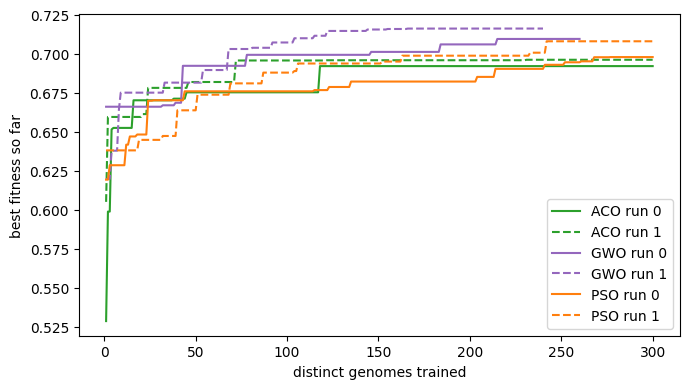

method  run  genomes  best_fitness  mean_fitness  mean_gates  seconds_per_eval
   ACO    0      300         0.692         0.635      17.277            20.130
   ACO    1      300         0.696         0.634       9.453            14.551
   GWO    0      260         0.709         0.664      11.727            15.559
   GWO    1      240         0.716         0.665       6.454            13.422
   PSO    0      300         0.698         0.654      14.940            14.851
   PSO    1      300         0.708         0.658       9.107            13.474


In [12]:
log_df = pd.DataFrame(log)
colors = {"PSO": "tab:orange", "ACO": "tab:green", "GWO": "tab:purple"}
plt.figure(figsize=(7, 4))
for (method, run), g in log_df.groupby(["method", "run"]):
    g = g.sort_values("eval")
    if run == 0:
        plt.plot(g["eval"], g["fitness"].cummax(), color=colors[method], label=f"{method} run {run}")
    else:
        plt.plot(g["eval"], g["fitness"].cummax(), "--", color=colors[method], label=f"{method} run {run}")
plt.xlabel("distinct genomes trained")
plt.ylabel("best fitness so far")
plt.legend()
plt.tight_layout()
plt.savefig(f"{out_dir}/convergence.png", dpi=150)
plt.show()

summary = log_df.groupby(["method", "run"]).agg(genomes=("eval", "max"), best_fitness=("fitness", "max"),
                                                 mean_fitness=("fitness", "mean"), mean_gates=("gates", "mean"),
                                                 seconds_per_eval=("seconds", "mean")).reset_index()
summary.to_csv(f"{out_dir}/summary.csv", index=False)
print(summary.round(3).to_string(index=False))

## final pick

the top 3 of each run retrained with the full recipe, the best on val is the run's circuit.

In [13]:
def retrain(item):
    method, run, rank, sg = item
    g = to_circuit(sg)
    torch.manual_seed(0)
    model = QuantumClassifier(g)
    train(model, angles["train"][:, g["mask"]], y_train, lr=lr, epochs=epochs, batch_size=batch_size, seed=0)
    row = {"method": method, "run": run, "rank": rank, "key": key_of(sg), "gates": two_qubit_gates(g), "weights": n_weights(g)}
    row.update(score(predict(model, angles["val"][:, g["mask"]])))
    return row


items = []
for (method, run), cache in caches.items():
    top = sorted(cache.values(), key=lambda r: r["fitness"], reverse=True)[:top_k]
    for rank, r in enumerate(top):
        items.append((method, run, rank + 1, json.loads(r["genome"])))

with mp.get_context("fork").Pool(os.cpu_count()) as pool:
    final = pd.DataFrame(pool.map(retrain, items))
final.to_csv(f"{out_dir}/top_retrained.csv", index=False)

picks = final.loc[final.groupby(["method", "run"])["video auc"].idxmax()]
picks.to_csv(f"{out_dir}/final_picks.csv", index=False)
print(picks[["method", "run", "key", "video auc", "ci low", "ci high", "gates"]].round(3).to_string(index=False))

method  run                                                      key  video auc  ci low  ci high  gates
   ACO    0 m3.8.9.11.12.16.17.21|RX|RY/cz_ring-Rot/cz_ring-Rot/none      0.698   0.653    0.740     16
   ACO    1                  m8.9.10.14.15.17.21.28|RY|RX+RY/cz_ring      0.695   0.651    0.738      8
   GWO    0                    m3.7.8.10.16.17.21.24|H+RZ|RX+RY/none      0.710   0.663    0.750      0
   GWO    1               m1.3.8.9.10.17.21.23|RX|RY/none-RX+RY/none      0.700   0.656    0.744      0
   PSO    0            m2.3.7.8.10.17.21.28|H+RZ|Rot/cz_ring-RY/none      0.717   0.672    0.761      8
   PSO    1                    m2.3.8.10.16.17.21.27|H+RZ|RX+RY/none      0.704   0.660    0.748      0
